# Kết hợp HSV + HOG và đánh giá chung

**Phạm vi:** kết hợp màu/hình dạng, chọn trọng số/k/khoảng cách bằng validation, lưu mô hình,
khóa cấu hình rồi so sánh ba phương pháp trên test chính thức. 

## 1. Thư viện và cấu hình dùng chung

In [1]:
# %pip install numpy pandas opencv-python matplotlib scikit-learn joblib threadpoolctl
from pathlib import Path
import sys, json, inspect, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image

PROJECT=Path.cwd()
if PROJECT.name=="code":
    PROJECT=PROJECT.parent
sys.path.insert(0,str(PROJECT/"code"))
from features_combined import combine_features
from train_combined import run_training
from evaluate_test import evaluate
from plot_validation import plot_results as plot_validation
from plot_test import plot_results as plot_test

OUTPUT=PROJECT/"results/combined"
OUTPUT.mkdir(parents=True,exist_ok=True)
print("Dự án:",PROJECT.resolve())


def table_html(html):
    import re
    html = re.sub(r"<style.*?</style>", "", html, flags=re.DOTALL)
    header = "color:#172b4d !important;background:#e8eef5 !important;padding:8px 12px;border:1px solid #ccd5df;white-space:nowrap;"
    body = "color:#172b4d !important;background:#ffffff !important;padding:8px 12px;border:1px solid #ccd5df;white-space:nowrap;"
    html = re.sub(r"<th(?=[ >])", '<th style="' + header + '"', html)
    html = re.sub(r"<td(?=[ >])", '<td style="' + body + '"', html)
    html = html.replace("<table ", '<table style="border-collapse:collapse;font-family:Arial,sans-serif;font-size:13px;" ')
    return '<div style="background:#fff;color:#172b4d;padding:10px;max-width:100%;overflow-x:auto;">' + html + '</div>'


def show_table(table):
    # Series (một cột) được chuyển thành bảng trước khi hiển thị.
    if isinstance(table, pd.Series):
        table = table.to_frame(name="Giá trị")
    display(HTML(table_html(table.to_html(border=0))))

Dự án: C:\Users\Dat\Documents\Study\Projects\XLA_N7_CT


## 2. Kết hợp đặc trưng như thế nào?

Lấy HSV và HOG từ **cùng ảnh BGR**, cùng resize 64×64 và hàm của người 2–3.
Cố định bins HSV `(16,4,4)` và HOG cell 8 từ kết quả validation trước đó.

Chuẩn hóa L2 riêng mỗi nhóm, rồi ghép:
`x = [alpha * HSV_L2, (1-alpha) * HOG_L2]`.

- HSV: 256 chiều; HOG: 1.764 chiều; vector ghép: **2.020 chiều**.
- `alpha=0.25`: hệ số màu 0.25, hình dạng 0.75; `alpha=0.5`: hai hệ số bằng nhau.
- Các hệ số không phải xác suất hoặc bảo đảm phần trăm đóng góp vào quyết định.
  Với Euclidean, khoảng cách bình phương dùng hệ số bình phương; Manhattan dùng hệ số tuyến tính,
  và L2 mỗi nhóm không bảo đảm độ lớn L1 hai nhóm bằng nhau.
- Không học scaler từ validation/test; nhóm vector 0 vẫn giữ 0 để tránh NaN.

Đây là hàm thật được dùng (hiển thị bằng văn bản để không lỗi màu theme):

In [2]:
print(inspect.getsource(combine_features))
# Ví dụ nhỏ chỉ để hiểu hệ số, không phải dữ liệu thực nghiệm.
color=np.array([3,4],dtype=np.float32)
shape=np.array([1,2,2],dtype=np.float32)
example=combine_features(color,shape,0.25)
print("Vector ví dụ:",example)
print("Chuẩn nhóm màu:",np.linalg.norm(example[:2]))
print("Chuẩn nhóm hình dạng:",np.linalg.norm(example[2:]))

def combine_features(hsv, hog, hsv_weight=0.25):
    """x = [alpha * HSV_L2, (1-alpha) * HOG_L2]."""
    if not 0 < hsv_weight < 1:
        raise ValueError('Trọng số HSV phải nằm giữa 0 và 1')
    if np.shape(hsv)[:-1] != np.shape(hog)[:-1]:
        raise ValueError('Hai nhóm phải khớp số ảnh và thứ tự ảnh')
    color = hsv_weight * normalize_l2(hsv)
    shape = (1 - hsv_weight) * normalize_l2(hog)
    return np.concatenate([color, shape], axis=-1)

Vector ví dụ: [0.15 0.2  0.25 0.5  0.5 ]
Chuẩn nhóm màu: 0.25
Chuẩn nhóm hình dạng: 0.75


## 3. Tìm tham số trên validation

Giữ split người 1: **31.380 train / 7.829 validation**, không trùng track.
Grid: alpha `0.25/0.5` × k `3/5/7` × Euclidean/Manhattan = **12 cấu hình kết hợp mới**.
Bỏ phiếu uniform, brute force và 4 thread như hai phương pháp trước.
Chọn Macro-F1; hòa thì Accuracy, ít chiều, k nhỏ, thứ tự grid.

**Công bố ngân sách:** HSV có 12 lần thử, HOG có 12 lần thử và ghép có 12 lần thử mới.
Ghép kế thừa bins/cell đã chọn từ hai thí nghiệm trước, nên đây là tìm kiếm tuần tự có điều kiện,
không phải ba quy trình tối ưu hoàn toàn độc lập, cùng tổng chi phí. Không dùng test cho bước này.

Mặc định xem kết quả. Chạy lại grid có thể mất khá lâu do Manhattan trên 2.020 chiều.
Nếu đã khóa cấu hình/test thì giữ nguyên thí nghiệm; muốn làm thí nghiệm khác nên dùng bản sao dự án.

In [3]:
RUN_TRAINING=False
if RUN_TRAINING or not (OUTPUT/"summary.json").exists():
    assert not (PROJECT/"configs/final_experiment.json").exists(), "Thí nghiệm đã khóa, không chỉnh lại theo test"
    summary=run_training(PROJECT)
else:
    summary=json.loads((OUTPUT/"summary.json").read_text(encoding="utf-8"))
for name,expected in summary["split_sha256"].items():
    assert hashlib.sha256((PROJECT/f"splits/{name}.csv").read_bytes()).hexdigest()==expected

results=pd.read_csv(OUTPUT/"validation_results.csv")
columns=["hsv_weight","hog_weight","k","distance","n_features","accuracy","macro_f1",
         "classifier_ms_per_image","end_to_end_ms_per_image"]
show_table(results.sort_values(["macro_f1","accuracy"],ascending=False)[columns].round(4))
print("Cấu hình chọn:")
show_table(pd.Series(summary["best"]))

,hsv_weight,hog_weight,k,distance,n_features,accuracy,macro_f1,classifier_ms_per_image,end_to_end_ms_per_image
5,0.25,0.75,7,manhattan,2020,0.8027,0.7623,22.4442,40.8761
3,0.25,0.75,5,manhattan,2020,0.8001,0.7616,42.3162,60.7481
1,0.25,0.75,3,manhattan,2020,0.7929,0.7545,21.5217,39.9536
9,0.50,0.50,5,manhattan,2020,0.7373,0.6986,166.0266,184.4661
11,0.50,0.50,7,manhattan,2020,0.7379,0.6979,96.9679,98.3234
7,0.50,0.50,3,manhattan,2020,0.7313,0.6884,21.8042,40.2437
4,0.25,0.75,7,euclidean,2020,0.6913,0.6544,3.4949,21.9268
2,0.25,0.75,5,euclidean,2020,0.6899,0.6515,1.9683,20.4002
0,0.25,0.75,3,euclidean,2020,0.6903,0.6494,4.0343,22.4662
6,0.50,0.50,3,euclidean,2020,0.4271,0.3519,2.1737,20.6132


Cấu hình chọn:


,Giá trị
hsv_weight,0.25
hog_weight,0.75
h_bins,16
s_bins,4
v_bins,4
cell_size,8
k,7
distance,manhattan
weights,uniform
n_features,2020


## 4. So sánh cả ba phương pháp trên validation

Bảng là các mô hình được chọn bằng validation, chưa phải điểm test.
Không mặc định ghép tốt hơn; xem số liệu thực tế.
Thời gian là một lượt batch chia số ảnh, không phải phép đo latency một ảnh lặp nhiều lần. Phiên validation có gián đoạn kênh điều khiển nên có số đo thời gian bất thường; không dùng các thời gian này để xếp hạng tốc độ.

,method,split,search_budget,accuracy,macro_f1,n_features,k,distance,classifier_ms_per_image,end_to_end_ms_per_image
0,HSV + kNN,validation,12,0.1745,0.1341,256,3,manhattan,2.4781,2.8828
1,HOG + kNN,validation,12,0.8219,0.7761,1764,7,manhattan,18.1186,19.0872
2,HSV + HOG + kNN,validation,12,0.8027,0.7623,2020,7,manhattan,22.4442,40.8761


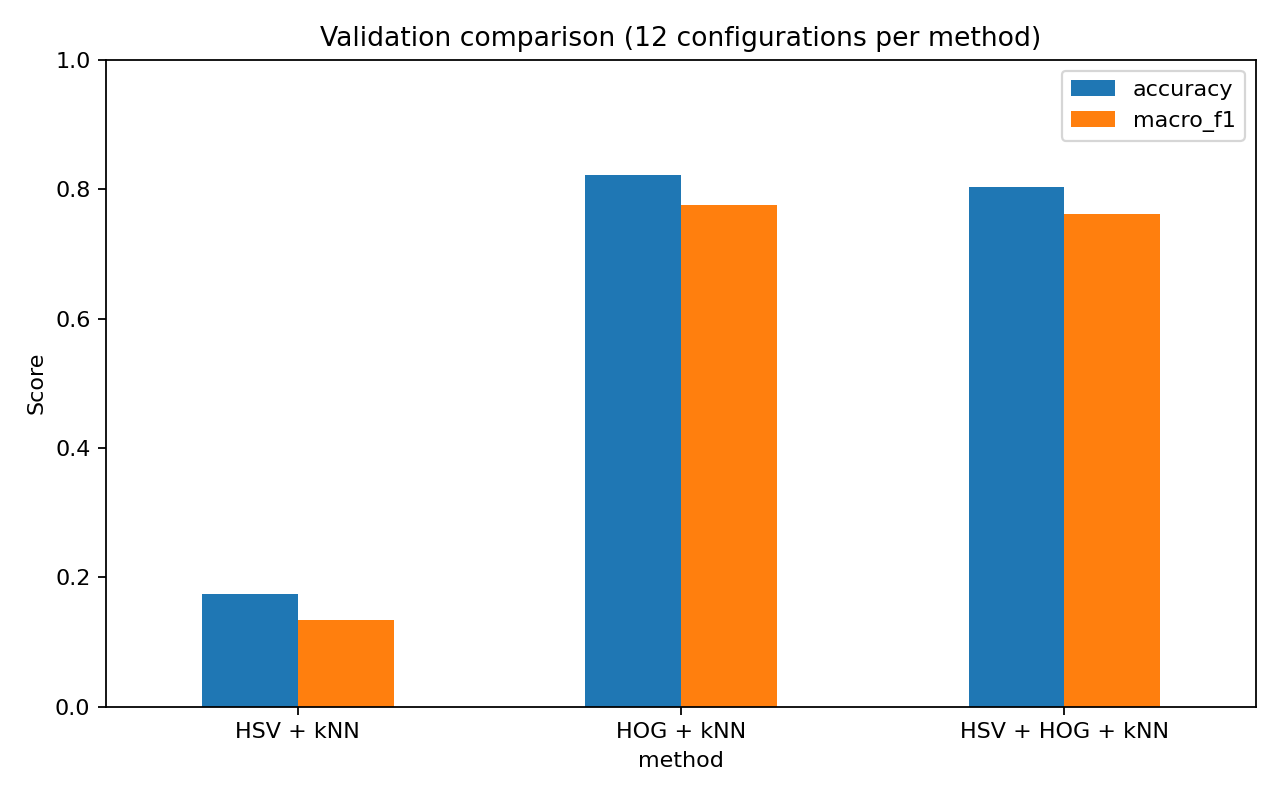

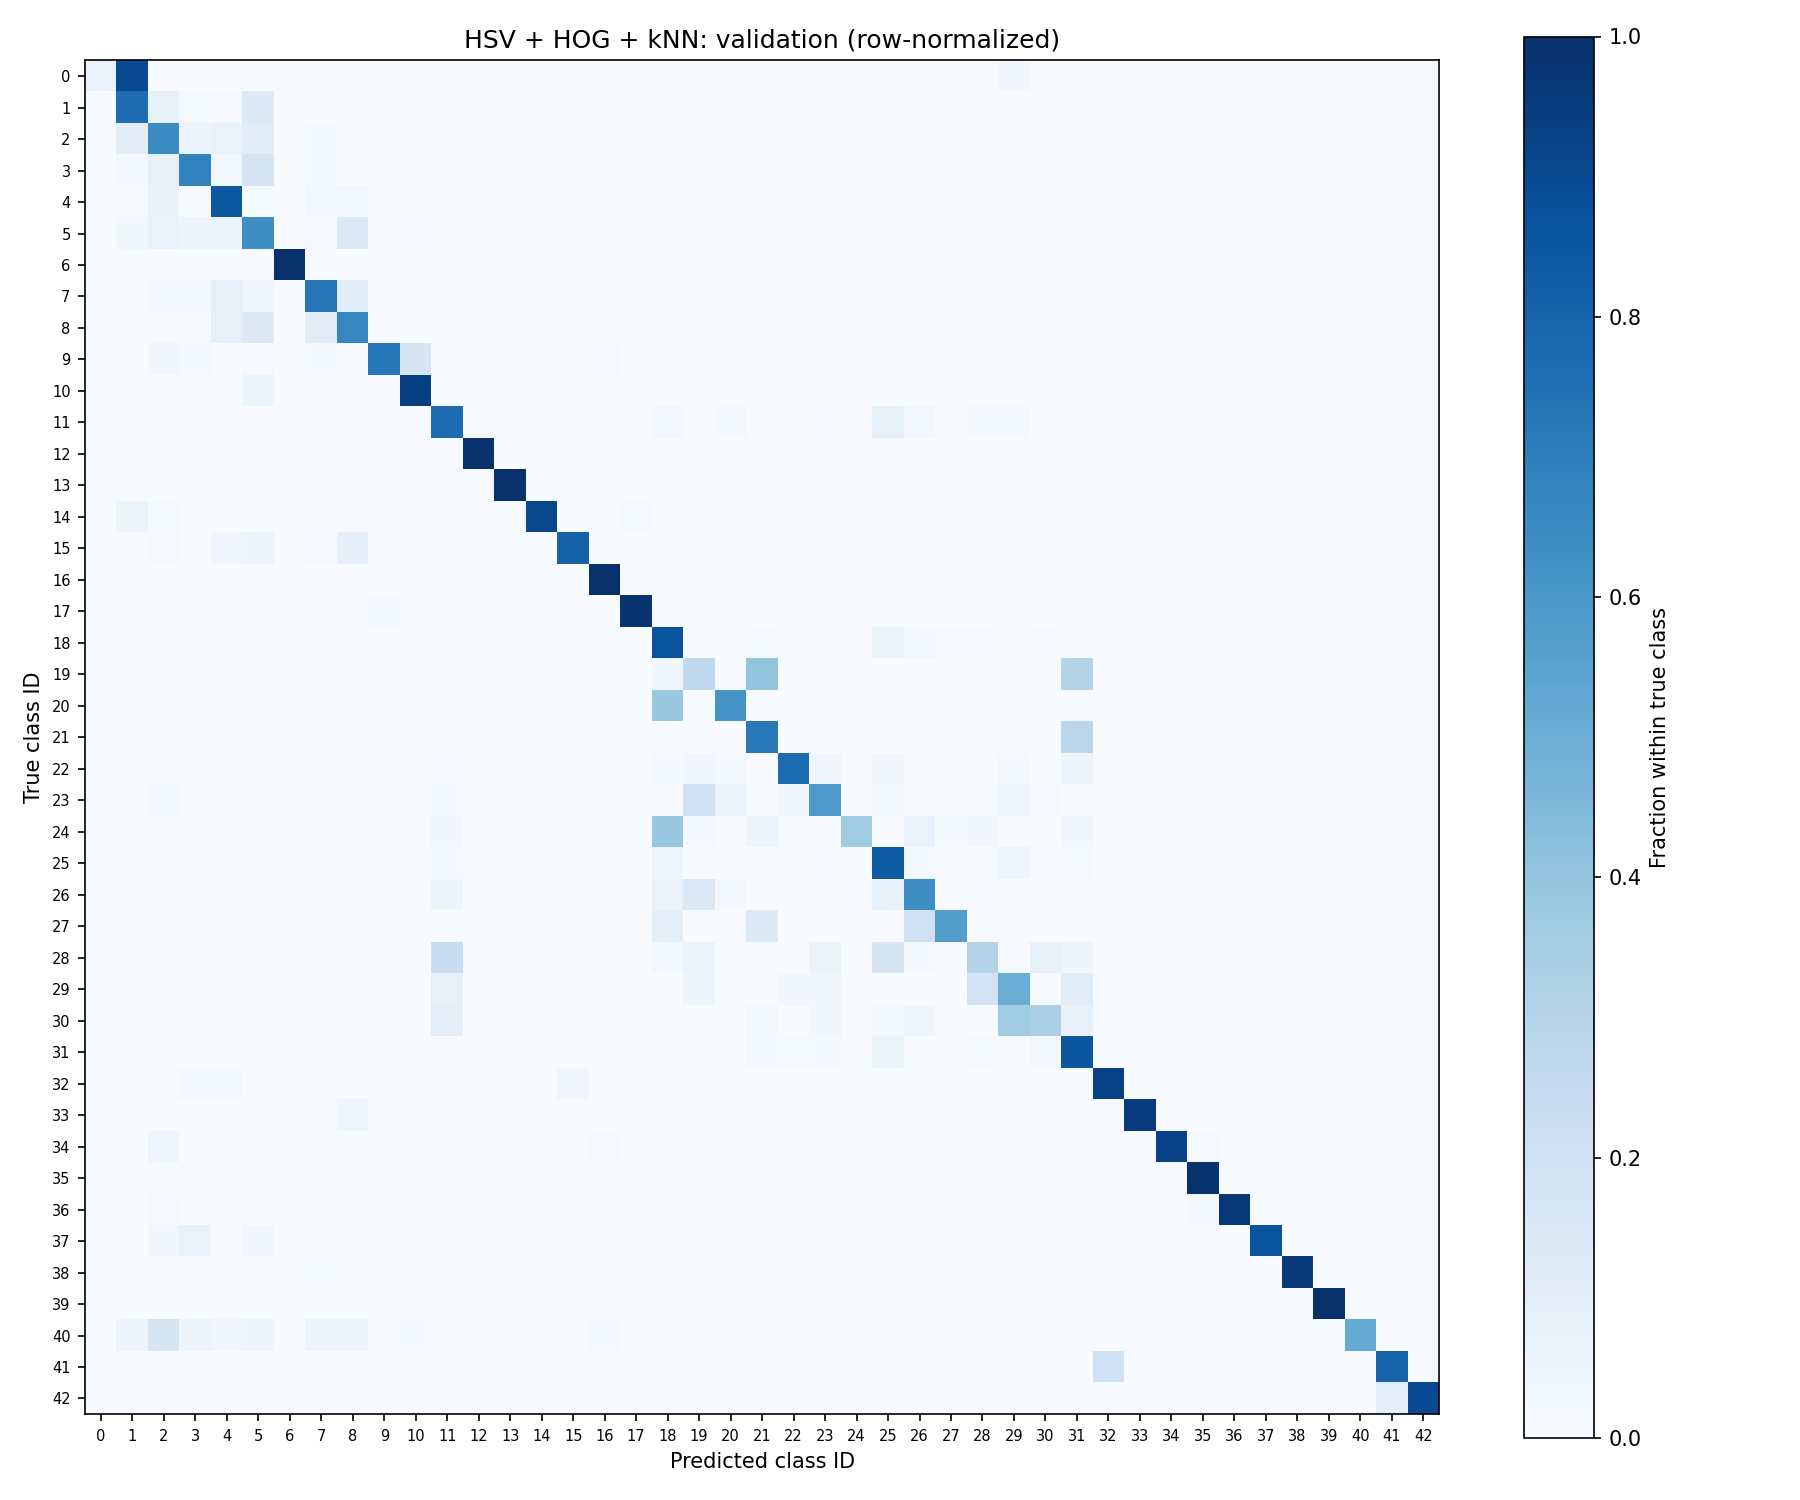

In [4]:
validation_comparison=plot_validation(PROJECT,include_combined=True)
show_table(validation_comparison.round(4))
display(Image(filename=str(PROJECT/"results/comparison/validation_comparison_all.png")))
display(Image(filename=str(OUTPUT/"validation_confusion_matrix.png")))

## 5. Khóa cấu hình và đánh giá test chính thức

`evaluate_test.py` lưu `configs/final_experiment.json` với tham số và hash cả ba mô hình/split
**trước khi đọc nhãn test**. Không fit lại hoặc đổi cấu hình dựa trên test.
Cả ba mô hình vẫn chỉ được huấn luyện trên 31.380 ảnh train, không gộp validation.

Đánh giá **12.630 ảnh test chính thức** với cùng hàm đặc trưng khi huấn luyện.
Xuất Accuracy, Macro-F1, Precision/Recall/F1 từng lớp, dự đoán từng ảnh, ma trận và thời gian.
Đã có kết quả thì hàm dùng lại; hash khác sẽ dừng để tránh trộn hai thí nghiệm.
Nếu đang chạy dở có thể tiếp tục từ phương pháp đã hoàn tất.

Giữ `RUN_TEST=False` để xem kết quả đã lưu. Chỉ bật khi đã chốt cấu hình và chưa đánh giá test.

,method,n_images,accuracy,macro_f1,n_features,classifier_ms_per_image,end_to_end_ms_per_image
0,HSV + kNN,12630,0.1699,0.1500,256,4.6924,5.2818
1,HOG + kNN,12630,0.8055,0.7767,1764,57.0575,57.8098
2,HSV + HOG + kNN,12630,0.7929,0.7644,2020,79.3609,80.4688


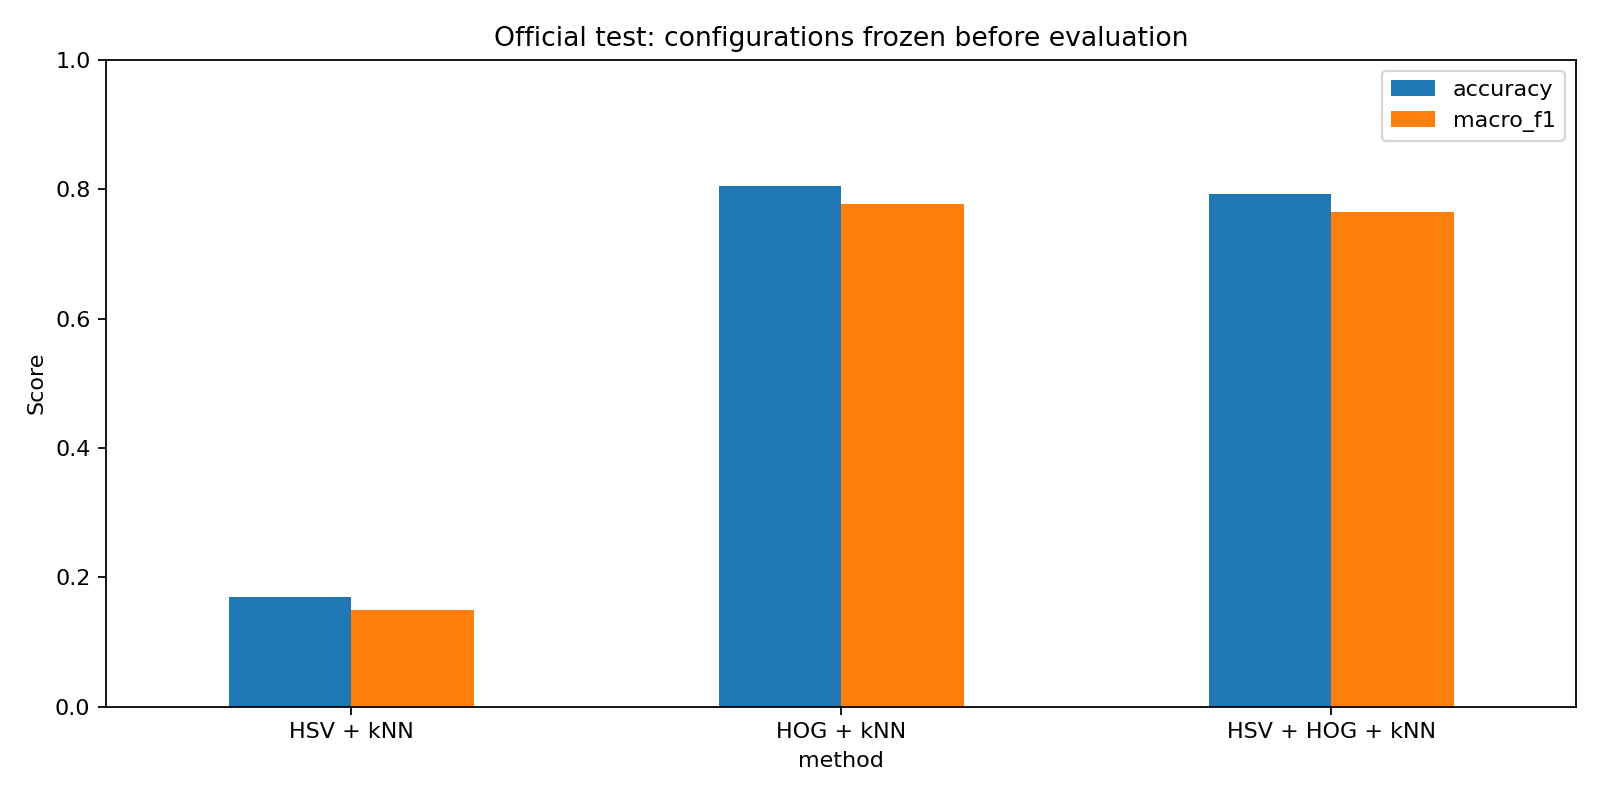

In [5]:
RUN_TEST=False
test_summary_path=PROJECT/"results/test/summary.json"
if RUN_TEST:
    test_summary=evaluate(PROJECT)
elif test_summary_path.exists():
    test_summary=json.loads(test_summary_path.read_text(encoding="utf-8"))
else:
    raise RuntimeError("Chưa đánh giá test: chỉ bật RUN_TEST sau khi chốt cả ba cấu hình")

show_columns=["method","n_images","accuracy","macro_f1","n_features",
              "classifier_ms_per_image","end_to_end_ms_per_image"]
test_comparison=plot_test(PROJECT)
show_table(test_comparison[show_columns].round(4))
display(Image(filename=str(PROJECT/"results/test/comparison.png")))

## 6. Ma trận, ảnh đúng/sai và những trường hợp kết hợp thay đổi kết quả

Ma trận chuẩn hóa theo hàng để lớp ít ảnh vẫn nhìn được, CSV lưu số đếm gốc.
Ba ảnh đúng và ba ảnh sai được lấy theo thứ tự CSV, ưu tiên lớp khác nhau, không chỉ ảnh đẹp.
Phân tích lỗi sau test chỉ để thảo luận, không dùng để đổi mô hình trong thí nghiệm này.

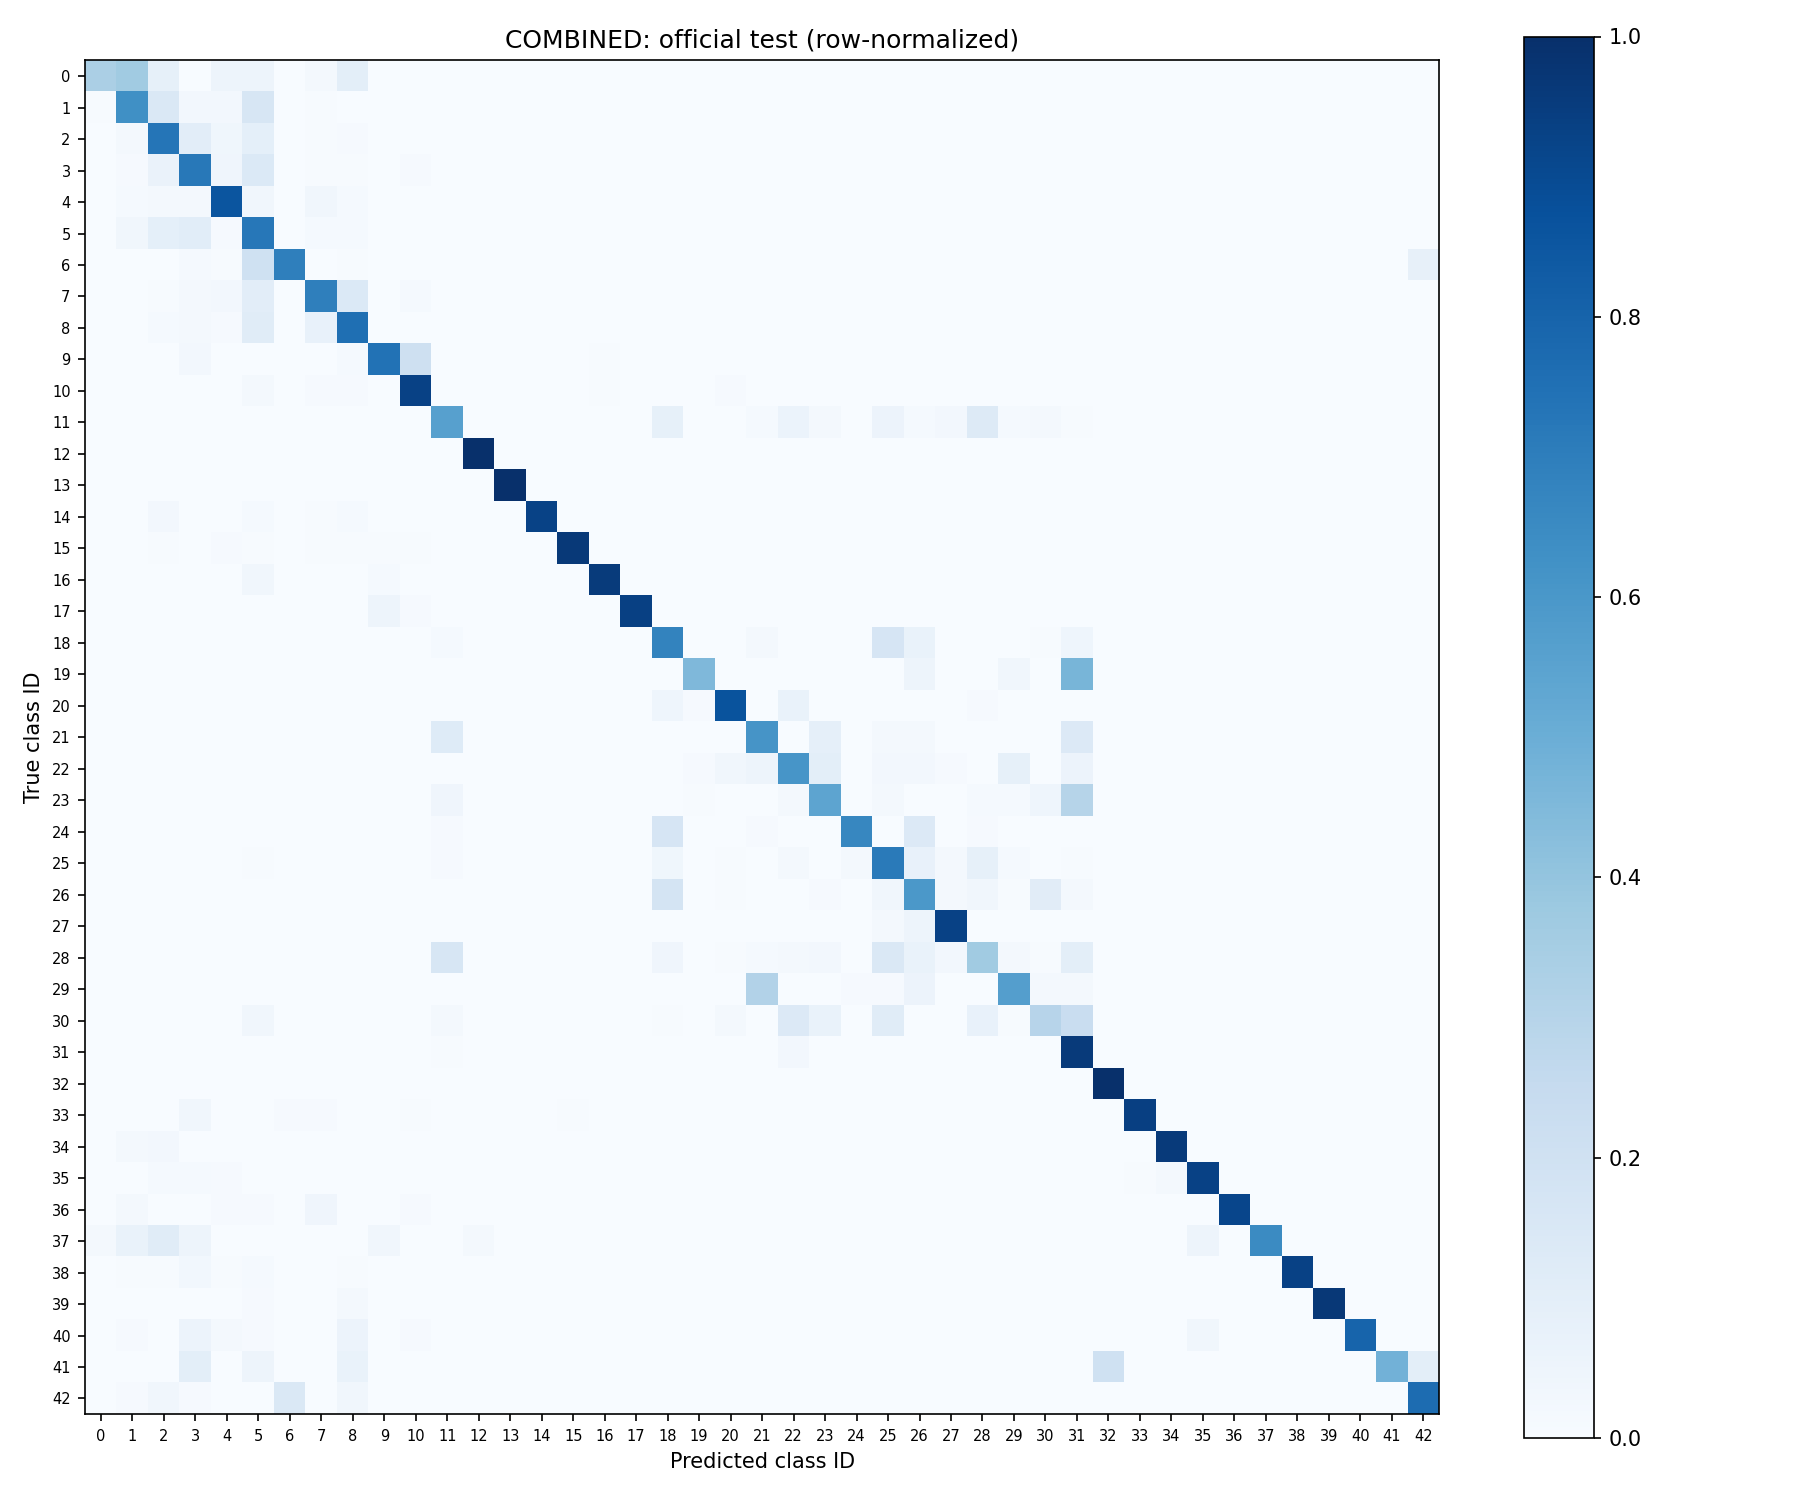

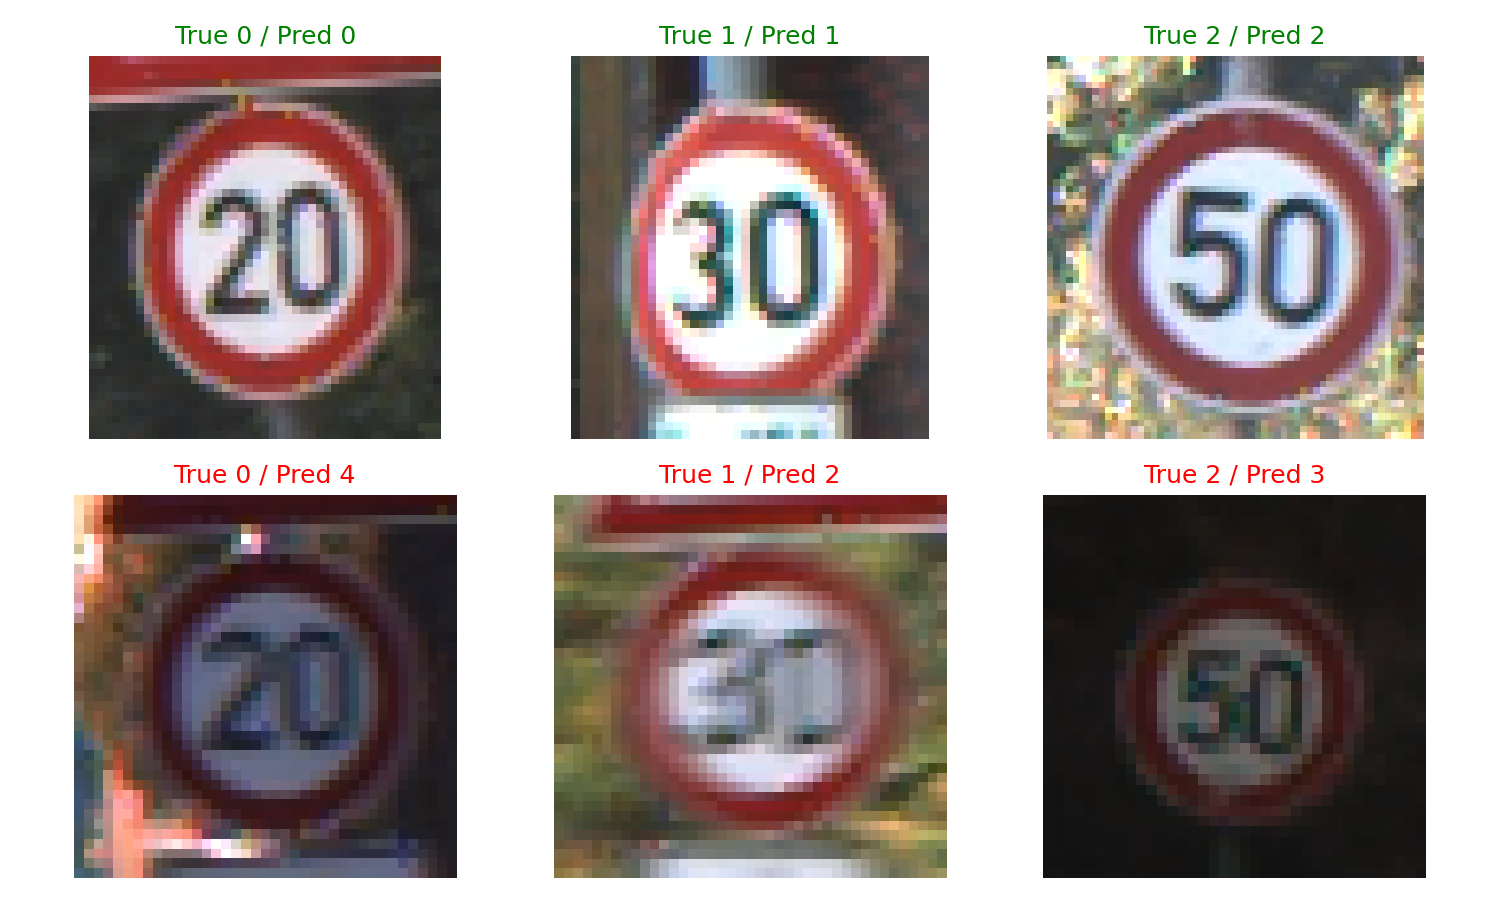

,Giá trị
"HOG sai, ghép đúng",429
"HOG đúng, ghép sai",588
Cả hai đúng,9585
Cả hai sai,2028


,class_id,precision,recall,f1-score,support
0,0,0.8333,0.3333,0.4762,60.0
1,1,0.8436,0.6292,0.7208,720.0
2,2,0.6858,0.7333,0.7088,750.0
3,3,0.5594,0.7222,0.6305,450.0
4,4,0.8373,0.8576,0.8473,660.0
5,5,0.5039,0.7238,0.5941,630.0
6,6,0.8739,0.6933,0.7732,150.0
7,7,0.7647,0.6933,0.7273,450.0
8,8,0.7164,0.7578,0.7365,450.0
9,9,0.9299,0.7458,0.8277,480.0


In [6]:
display(Image(filename=str(PROJECT/"results/test/combined/confusion_matrix.png")))
display(Image(filename=str(PROJECT/"results/test/combined/examples.png")))

hog=pd.read_csv(PROJECT/"results/test/hog/predictions.csv")
combined=pd.read_csv(PROJECT/"results/test/combined/predictions.csv")
paired=hog.merge(combined,on=["path","true_class"],suffixes=("_hog","_combined"),validate="one_to_one")
counts=pd.Series({
    "HOG sai, ghép đúng":int((~paired.correct_hog & paired.correct_combined).sum()),
    "HOG đúng, ghép sai":int((paired.correct_hog & ~paired.correct_combined).sum()),
    "Cả hai đúng":int((paired.correct_hog & paired.correct_combined).sum()),
    "Cả hai sai":int((~paired.correct_hog & ~paired.correct_combined).sum()),
})
show_table(counts)
paired.to_csv(OUTPUT/"test_paired_with_hog.csv",index=False)
wrong=combined[~combined.correct]
pairs=wrong.groupby(["true_class","predicted_class"]).size().sort_values(ascending=False)
show_table(pairs.head(10).rename("number_of_errors").to_frame())
show_table(pd.read_csv(PROJECT/"results/test/combined/per_class.csv").round(4))

## 7. Bàn giao

- `features_combined.py`: chuẩn hóa từng nhóm, ghép trọng số, trích từ cùng ảnh.
- `dataset_images.py`: đọc ảnh từ ZIP gốc hoặc thư mục, không đổi pixel.
- `train_combined.py`: 12 cấu hình validation; `models/combined_knn.joblib`: mô hình đã lưu cùng cấu hình.
- `model_features.py`: chọn đúng hàm đặc trưng cho từng mô hình khi đánh giá.
- `evaluate_test.py`: khóa cấu hình, đánh giá chính thức và dùng lại kết quả nếu đã có.
- `plot_validation.py`, `plot_test.py`: biểu đồ và ma trận từ CSV.
- `results/combined/`: kết quả validation của ghép; `results/test/`: kết quả chính thức ba phương pháp.
- `reports/combined_knn.md`: phương pháp ghép và tổng hợp kết quả, giới hạn thí nghiệm.

HOG giữ hình dạng, HSV giữ phân bố màu; kết hợp có thể giúp một số ảnh và làm sai ảnh khác.
